In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Update the path to match your folder structure
base_path = "al142019_best_track"

track_line = gpd.read_file(f"{base_path}/AL142019_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL142019_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL142019_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL142019_windswath.shp")

# Plot layers together
fig, ax = plt.subplots(figsize=(10,8))

wind_swath.plot(ax=ax, color="lightblue", alpha=0.5, edgecolor="none", label="Wind Swath")
wind_radii.plot(ax=ax, color="yellow", alpha=0.3, edgecolor="orange", label="Wind Radii")
track_line.plot(ax=ax, color="red", linewidth=2, label="Storm Track")
track_points.plot(ax=ax, marker="o", color="black", markersize=30, label="Track Points")

plt.title("Hurricane Melissa (AL142019)")
plt.legend()
plt.show()



DataSourceError: al142019_best_track/AL142019_lin.shp: No such file or directory

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Update the path to match your folder structure
base_path = "al092024_best_track"

track_line = gpd.read_file(f"{base_path}/al092024_lin.shp")
track_points = gpd.read_file(f"{base_path}/al092024_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/al092024_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/al092024_windswath.shp")

# Plot layers together
fig, ax = plt.subplots(figsize=(10,8))

wind_swath.plot(ax=ax, color="lightblue", alpha=0.5, edgecolor="none", label="Wind Swath")
wind_radii.plot(ax=ax, color="yellow", alpha=0.3, edgecolor="orange", label="Wind Radii")
track_line.plot(ax=ax, color="red", linewidth=2, label="Storm Track")
track_points.plot(ax=ax, marker="o", color="black", markersize=30, label="Track Points")

plt.title("Hurricane Helene (AL142019)")
plt.legend()
plt.show()



DataSourceError: al092024_best_track/al092024_lin.shp: No such file or directory

In [9]:
import os
os.listdir()

['main.ipynb', 'data']

In [10]:
import geopandas as gpd
import folium

gdf = gpd.read_file("data/al092024_best_track/al092024_best_track.kmz", driver="KML")

m = folium.Map(location=[20, -60], zoom_start=4)  # adjust center
for _, row in gdf.iterrows():
    sim_geo = gdf.iloc[[_]].to_json()
    folium.GeoJson(data=sim_geo).add_to(m)

m.save("hurricane_best_track.html")


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'al092024_best_track.kmz': 'Data' (default), 'Legend', 'bt_radii'. Specify layer parameter to avoid this warning.
  result = read_func(


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'al092024.kml': 'Data' (default), 'Legend', 'bt_radii'. Specify layer parameter to avoid this warning.
  result = read_func(


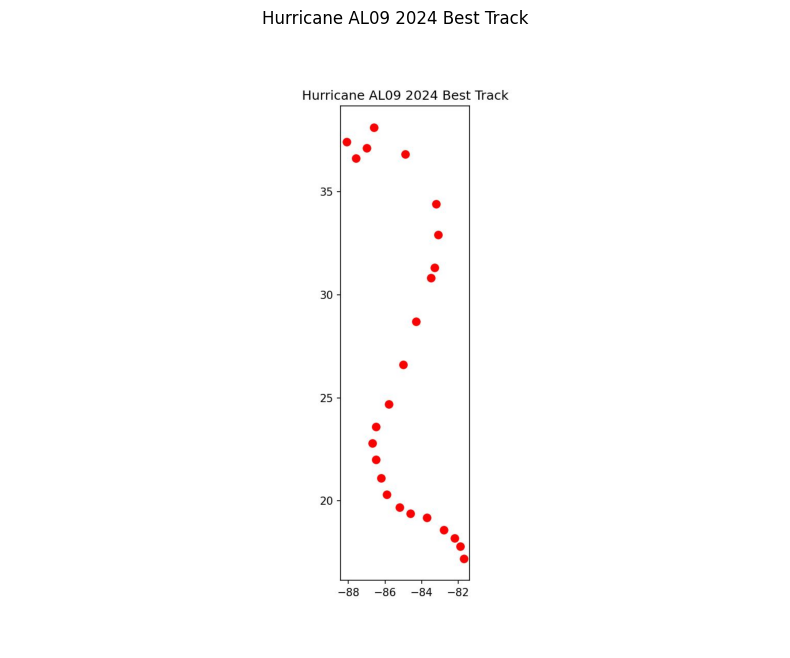

In [11]:
import geopandas as gpd
import zipfile
import os
import matplotlib.pyplot as plt
from PIL import Image

# Step 1: Unzip KMZ to extract the KML
with zipfile.ZipFile("data/al092024_best_track/al092024_best_track.kmz", 'r') as z:
    z.extractall("al092024_best_track")

# Step 2: Find the KML file inside
kml_file = [f for f in os.listdir("al092024_best_track") if f.endswith(".kml")][0]

# Step 3: Load with GeoPandas
gdf = gpd.read_file(f"al092024_best_track/{kml_file}", driver="KML")

# Step 4: Plot and save as JPG
fig, ax = plt.subplots(figsize=(10,8))
gdf.plot(ax=ax, color="red", linewidth=2)
plt.title("Hurricane AL09 2024 Best Track")
plt.savefig("best_track.jpg", dpi=150)

# Step 5: Display inline in Jupyter
img = Image.open("best_track.jpg")
plt.imshow(img)
plt.axis("off")
plt.show()


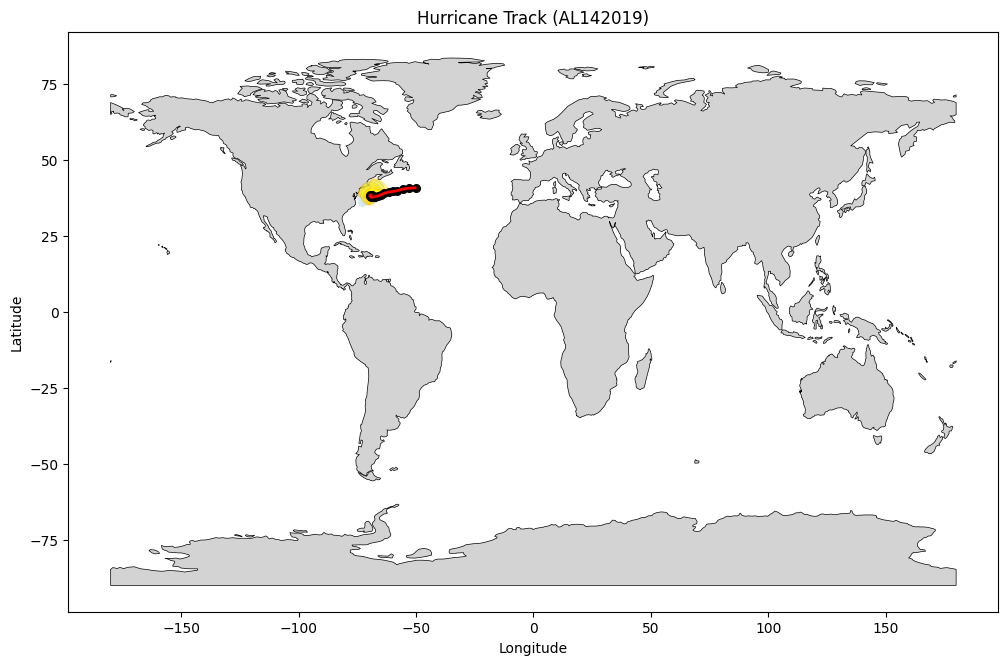

In [12]:
import geopandas as gpd
import matplotlib.pyplot as plt
import geodatasets

base_path = "data/al142019_best_track"

track_line = gpd.read_file(f"{base_path}/AL142019_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL142019_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL142019_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL142019_windswath.shp")

# Load country boundaries
world = gpd.read_file(
    geodatasets.get_path("naturalearth.land")
)

# Make sure everything uses the same coordinate system
world = world.to_crs(track_line.crs)

fig, ax = plt.subplots(figsize=(12, 8))

# -----------------------
# BASE MAP
# -----------------------

world.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

# -----------------------
# HURRICANE DATA
# -----------------------

wind_swath.plot(
    ax=ax,
    color="lightblue",
    alpha=0.5,
    edgecolor="none"
)

wind_radii.plot(
    ax=ax,
    color="yellow",
    alpha=0.3,
    edgecolor="orange"
)

track_line.plot(
    ax=ax,
    color="red",
    linewidth=2
)

track_points.plot(
    ax=ax,
    marker="o",
    color="black",
    markersize=30
)

plt.title("Hurricane Track (AL142019)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

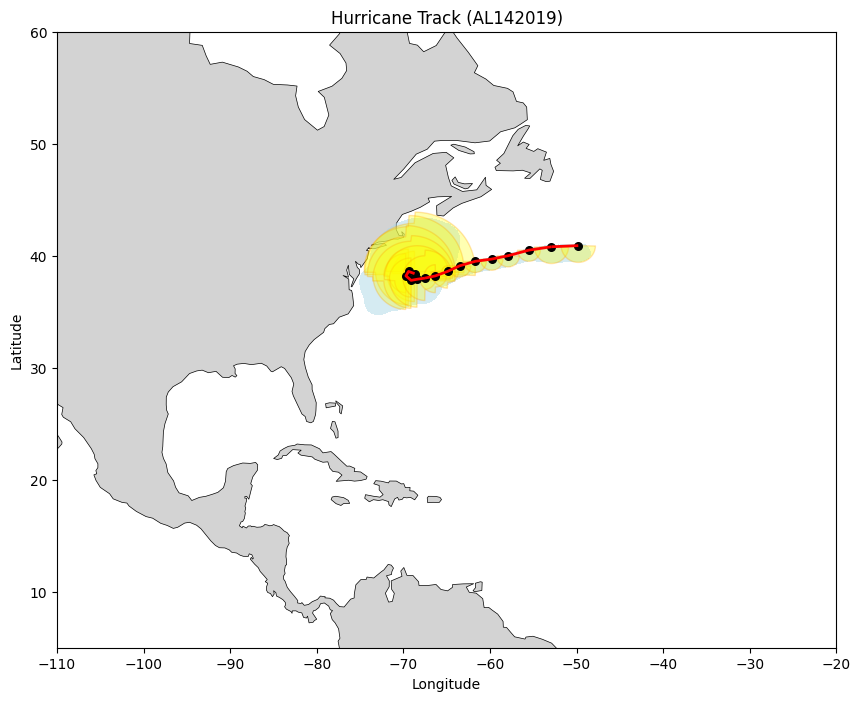

In [16]:
import geopandas as gpd
import matplotlib.pyplot as plt
import geodatasets

base_path = "data/al142019_best_track"

track_line = gpd.read_file(f"{base_path}/AL142019_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL142019_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL142019_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL142019_windswath.shp")

# Load country boundaries
world = gpd.read_file(
    geodatasets.get_path("naturalearth.land")
)

# Convert world data to same CRS
world = world.to_crs(track_line.crs)

# -----------------------
# LIMIT MAP TO REGION
# -----------------------

# North America + Caribbean bounding box
xmin, xmax = -110, -20
ymin, ymax = 5, 60

world_region = world.cx[xmin:xmax, ymin:ymax]

# -----------------------
# PLOT
# -----------------------

fig, ax = plt.subplots(figsize=(12, 8))

# Countries / land
world_region.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

# Wind swath
wind_swath.plot(
    ax=ax,
    color="lightblue",
    alpha=0.5,
    edgecolor="none"
)

# Wind radii
wind_radii.plot(
    ax=ax,
    color="yellow",
    alpha=0.3,
    edgecolor="orange"
)

# Hurricane track
track_line.plot(
    ax=ax,
    color="red",
    linewidth=2
)

# Track points
track_points.plot(
    ax=ax,
    marker="o",
    color="black",
    markersize=30
)

# Set map boundaries
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.title("Hurricane Track (AL142019)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

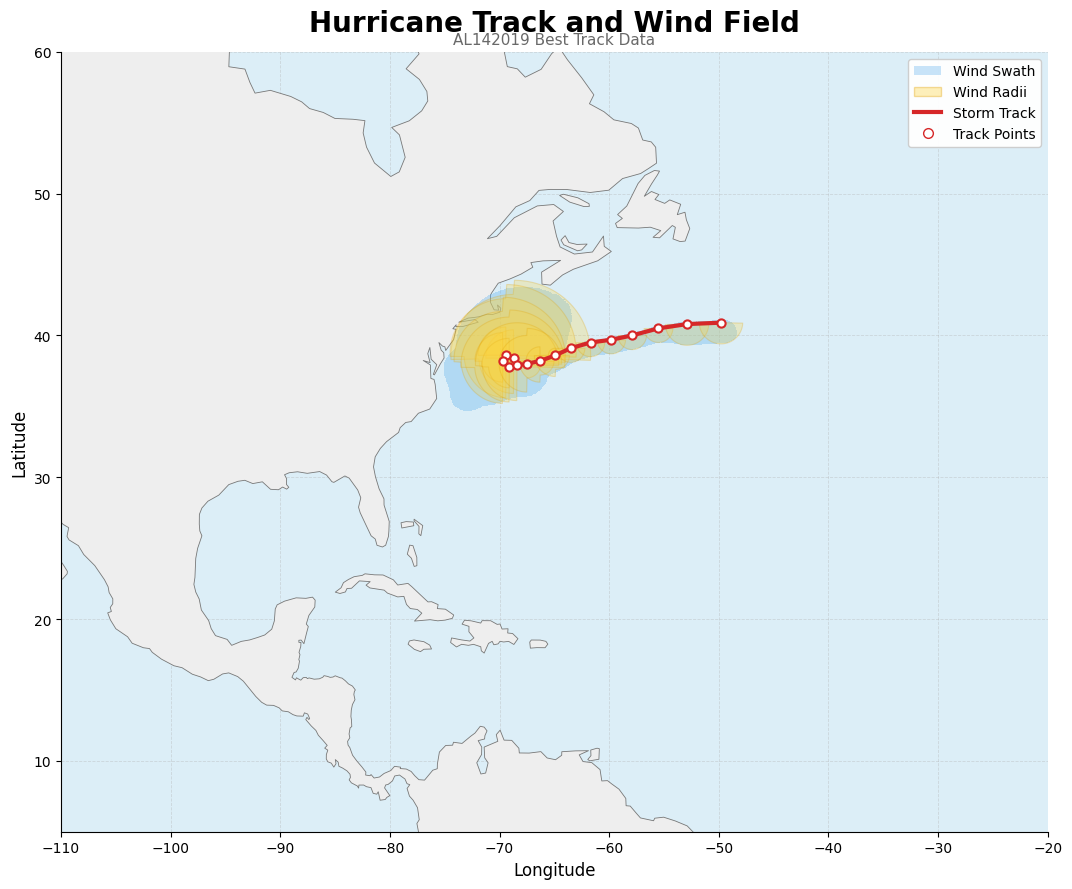

In [18]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import geodatasets

base_path = "data/al142019_best_track"

# -----------------------
# LOAD HURRICANE DATA
# -----------------------

track_line = gpd.read_file(f"{base_path}/AL142019_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL142019_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL142019_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL142019_windswath.shp")

# -----------------------
# LOAD BASE MAP
# -----------------------

world = gpd.read_file(
    geodatasets.get_path("naturalearth.land")
)

# Match coordinate reference system
world = world.to_crs(track_line.crs)

# -----------------------
# MAP EXTENT
# -----------------------

xmin, xmax = -110, -20
ymin, ymax = 5, 60

world_region = world.cx[xmin:xmax, ymin:ymax]

# -----------------------
# CREATE FIGURE
# -----------------------

fig, ax = plt.subplots(figsize=(14, 9))

# Ocean background
ax.set_facecolor("#dceef7")

# -----------------------
# BASE MAP
# -----------------------

world_region.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#777777",
    linewidth=0.6,
    zorder=1
)

# -----------------------
# WIND SWATH
# -----------------------

wind_swath.plot(
    ax=ax,
    color="#63b3ed",
    alpha=0.35,
    edgecolor="none",
    zorder=2
)

# -----------------------
# WIND RADII
# -----------------------

wind_radii.plot(
    ax=ax,
    color="#ffd43b",
    alpha=0.25,
    edgecolor="#e09f00",
    linewidth=0.8,
    zorder=3
)

# -----------------------
# HURRICANE TRACK
# -----------------------

track_line.plot(
    ax=ax,
    color="#d62728",
    linewidth=3,
    zorder=4
)

# -----------------------
# TRACK POINTS
# -----------------------

track_points.plot(
    ax=ax,
    marker="o",
    facecolor="white",
    edgecolor="#d62728",
    linewidth=1.5,
    markersize=35,
    zorder=5
)

# -----------------------
# MAP EXTENT
# -----------------------

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# -----------------------
# GRID
# -----------------------

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.4
)

# Put grid behind hurricane layers
ax.set_axisbelow(True)

# -----------------------
# TITLE
# -----------------------

ax.set_title(
    "Hurricane Track and Wind Field",
    fontsize=20,
    fontweight="bold",
    pad=15
)

ax.text(
    0.5,
    1.01,
    "AL142019 Best Track Data",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
    color="dimgray"
)

# -----------------------
# AXIS LABELS
# -----------------------

ax.set_xlabel(
    "Longitude",
    fontsize=12
)

ax.set_ylabel(
    "Latitude",
    fontsize=12
)

# -----------------------
# LEGEND
# -----------------------

legend_elements = [
    Patch(
        facecolor="#63b3ed",
        edgecolor="none",
        alpha=0.35,
        label="Wind Swath"
    ),
    Patch(
        facecolor="#ffd43b",
        edgecolor="#e09f00",
        alpha=0.35,
        label="Wind Radii"
    ),
    Line2D(
        [0],
        [0],
        color="#d62728",
        linewidth=3,
        label="Storm Track"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="white",
        markerfacecolor="white",
        markeredgecolor="#d62728",
        markersize=7,
        linewidth=0,
        label="Track Points"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True,
    framealpha=0.95,
    fontsize=10
)

# -----------------------
# CLEAN UP BORDERS
# -----------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

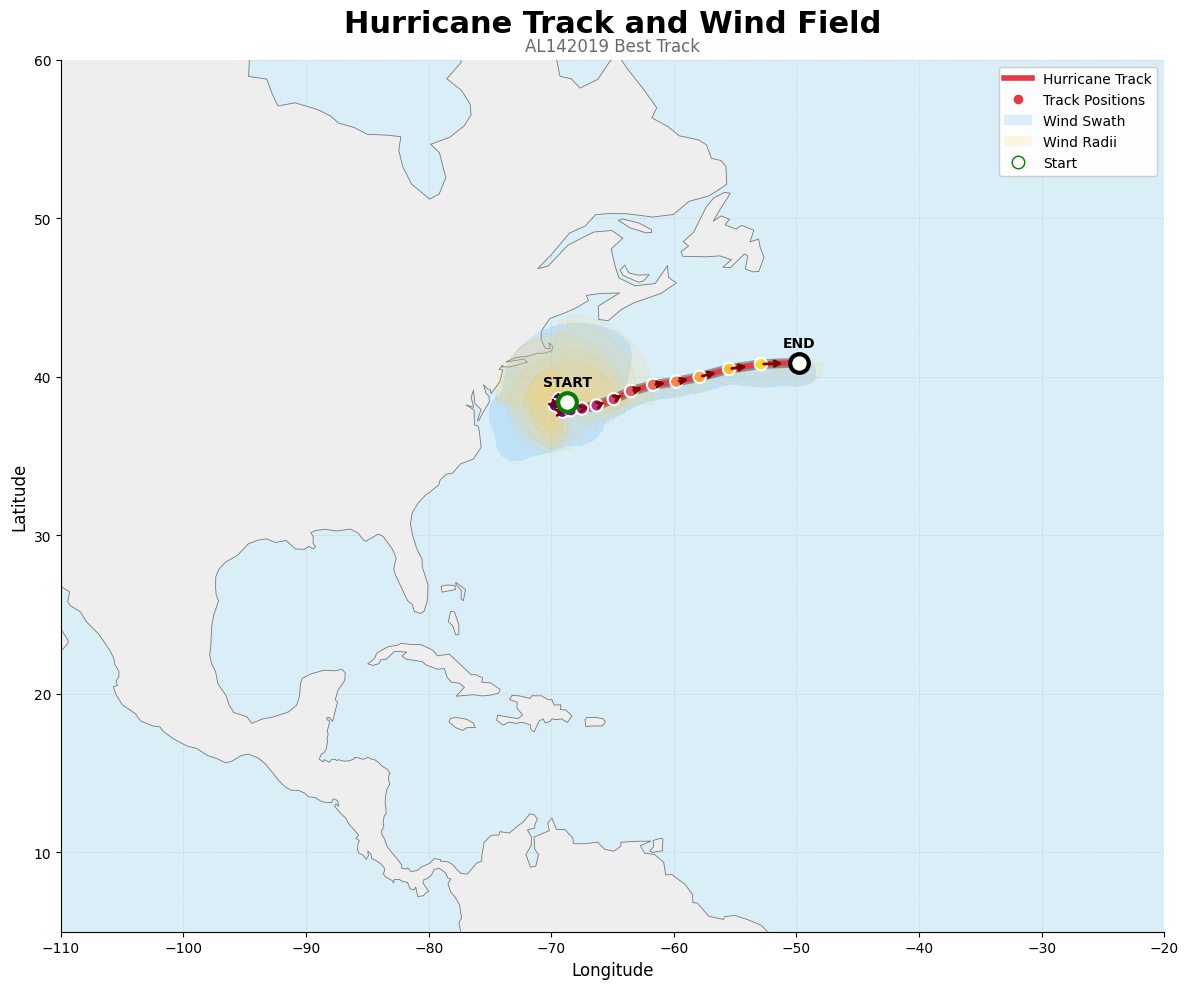

In [19]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np

base_path = "data/al142019_best_track"

# -----------------------
# LOAD DATA
# -----------------------

track_line = gpd.read_file(f"{base_path}/AL142019_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL142019_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL142019_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL142019_windswath.shp")

# -----------------------
# LOAD WORLD MAP
# -----------------------

import geodatasets

world = gpd.read_file(
    geodatasets.get_path("naturalearth.land")
)

world = world.to_crs(track_line.crs)

# -----------------------
# MAP EXTENT
# -----------------------

xmin, xmax = -110, -20
ymin, ymax = 5, 60

world_region = world.cx[xmin:xmax, ymin:ymax]

# -----------------------
# FIGURE
# -----------------------

fig, ax = plt.subplots(figsize=(15, 10))

# Ocean
ax.set_facecolor("#d9eef7")

# -----------------------
# LAND
# -----------------------

world_region.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#777777",
    linewidth=0.6,
    zorder=1
)

# -----------------------
# WIND SWATH
# -----------------------

wind_swath.plot(
    ax=ax,
    color="#4da6ff",
    alpha=0.18,
    edgecolor="none",
    zorder=2
)

# -----------------------
# WIND RADII
# -----------------------

wind_radii.plot(
    ax=ax,
    color="#ffd166",
    alpha=0.12,
    edgecolor="#e6a800",
    linewidth=0.5,
    zorder=3
)

# ==================================================
# HURRICANE PATH
# ==================================================

# Outer glow / halo
track_line.plot(
    ax=ax,
    color="black",
    linewidth=7,
    alpha=0.35,
    zorder=4
)

# Main track
track_line.plot(
    ax=ax,
    color="#e63946",
    linewidth=4,
    zorder=5
)

# -----------------------
# TRACK POINTS
# -----------------------

# Get coordinates from points
x = track_points.geometry.x.values
y = track_points.geometry.y.values

# Color points according to time/progression
progress = np.linspace(0, 1, len(track_points))

scatter = ax.scatter(
    x,
    y,
    c=progress,
    cmap="plasma",
    s=80,
    edgecolor="white",
    linewidth=1.5,
    zorder=6
)

# -----------------------
# DIRECTION ARROWS
# -----------------------

# Draw arrows every few points
step = max(1, len(x) // 10)

for i in range(0, len(x) - 1, step):

    dx = x[i + 1] - x[i]
    dy = y[i + 1] - y[i]

    ax.annotate(
        "",
        xy=(x[i] + dx * 0.65, y[i] + dy * 0.65),
        xytext=(x[i], y[i]),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=2,
            color="#7f0000"
        ),
        zorder=7
    )

# -----------------------
# START / END MARKERS
# -----------------------

ax.scatter(
    x[0],
    y[0],
    s=180,
    color="white",
    edgecolor="green",
    linewidth=3,
    zorder=8
)

ax.scatter(
    x[-1],
    y[-1],
    s=180,
    color="white",
    edgecolor="black",
    linewidth=3,
    zorder=8
)

# -----------------------
# LABEL START / END
# -----------------------

ax.text(
    x[0],
    y[0] + 1,
    "START",
    fontsize=10,
    fontweight="bold",
    ha="center",
    zorder=9
)

ax.text(
    x[-1],
    y[-1] + 1,
    "END",
    fontsize=10,
    fontweight="bold",
    ha="center",
    zorder=9
)

# -----------------------
# MAP LIMITS
# -----------------------

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# -----------------------
# GRID
# -----------------------

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.set_axisbelow(True)

# -----------------------
# TITLE
# -----------------------

ax.set_title(
    "Hurricane Track and Wind Field",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "AL142019 Best Track",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    color="dimgray"
)

# -----------------------
# AXES
# -----------------------

ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)

# -----------------------
# LEGEND
# -----------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        color="#e63946",
        linewidth=4,
        label="Hurricane Track"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="white",
        markerfacecolor="#e63946",
        markersize=8,
        linewidth=0,
        label="Track Positions"
    ),
    Patch(
        facecolor="#4da6ff",
        alpha=0.18,
        label="Wind Swath"
    ),
    Patch(
        facecolor="#ffd166",
        alpha=0.20,
        label="Wind Radii"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="white",
        markerfacecolor="white",
        markeredgecolor="green",
        markersize=9,
        linewidth=0,
        label="Start"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True,
    framealpha=0.95
)

# -----------------------
# CLEAN FRAME
# -----------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

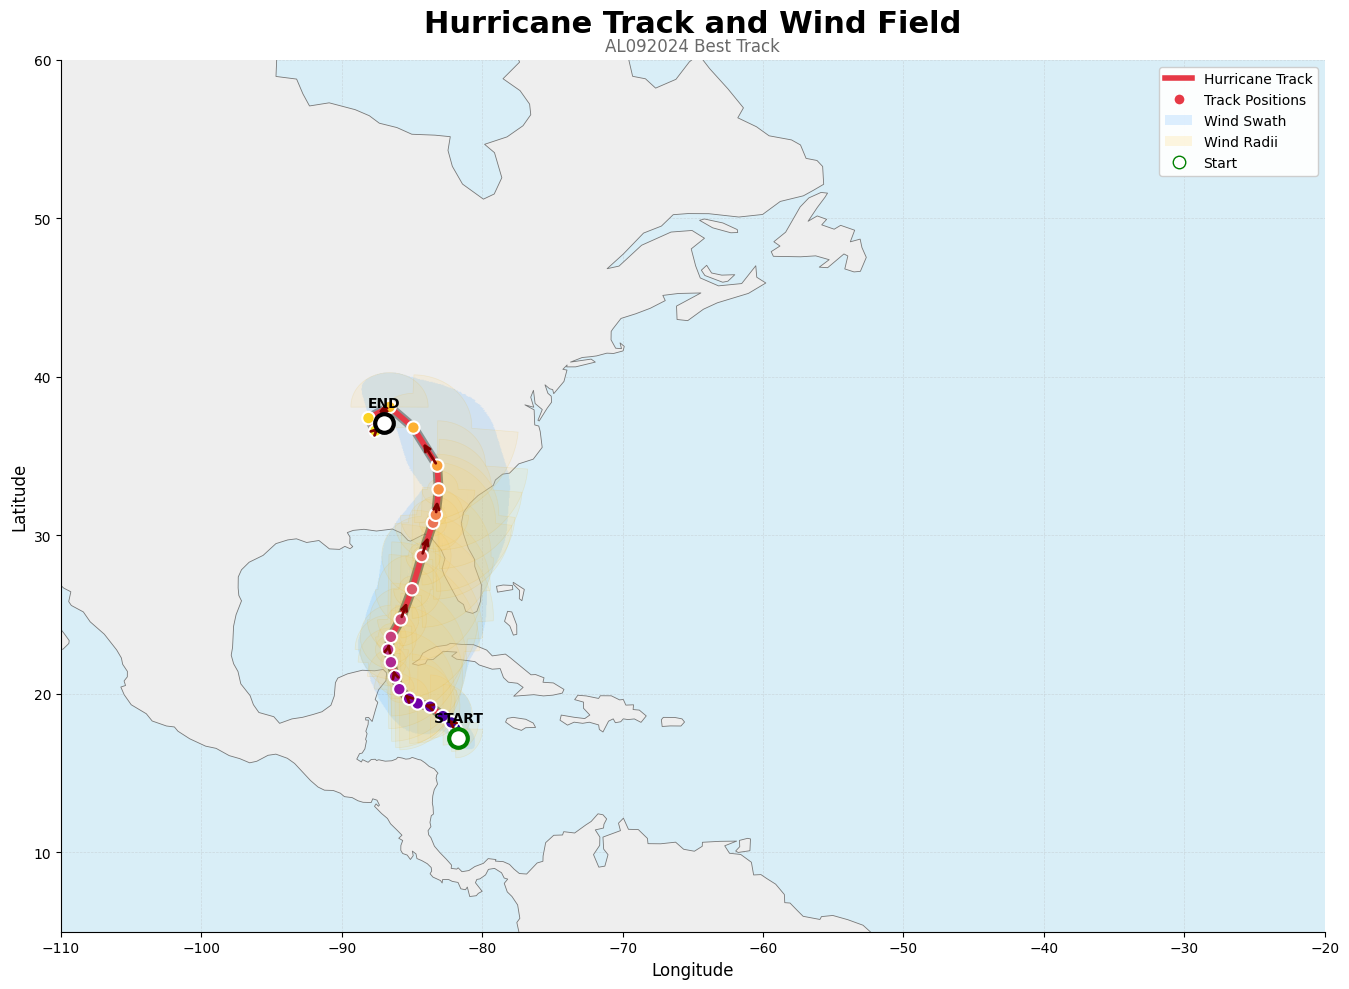

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import geodatasets

base_path = "data/al092024_best_track"

# -----------------------
# LOAD DATA
# -----------------------

track_line = gpd.read_file(f"{base_path}/AL092024_lin.shp")
track_points = gpd.read_file(f"{base_path}/AL092024_pts.shp")
wind_radii = gpd.read_file(f"{base_path}/AL092024_radii.shp")
wind_swath = gpd.read_file(f"{base_path}/AL092024_windswath.shp")

# -----------------------
# LOAD WORLD MAP
# -----------------------

world = gpd.read_file(
    geodatasets.get_path("naturalearth.land")
)

world = world.to_crs(track_line.crs)

# -----------------------
# MAP EXTENT
# -----------------------

xmin, xmax = -110, -20
ymin, ymax = 5, 60

world_region = world.cx[xmin:xmax, ymin:ymax]

# -----------------------
# FIGURE
# -----------------------

fig, ax = plt.subplots(figsize=(15, 10))

# Ocean
ax.set_facecolor("#d9eef7")

# -----------------------
# LAND
# -----------------------

world_region.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#777777",
    linewidth=0.6,
    zorder=1
)

# -----------------------
# WIND SWATH
# -----------------------

wind_swath.plot(
    ax=ax,
    color="#4da6ff",
    alpha=0.18,
    edgecolor="none",
    zorder=2
)

# -----------------------
# WIND RADII
# -----------------------

wind_radii.plot(
    ax=ax,
    color="#ffd166",
    alpha=0.12,
    edgecolor="#e6a800",
    linewidth=0.5,
    zorder=3
)

# ==================================================
# HURRICANE PATH
# ==================================================

# Outer glow / halo
track_line.plot(
    ax=ax,
    color="black",
    linewidth=7,
    alpha=0.35,
    zorder=4
)

# Main track
track_line.plot(
    ax=ax,
    color="#e63946",
    linewidth=4,
    zorder=5
)

# -----------------------
# TRACK POINTS
# -----------------------

x = track_points.geometry.x.values
y = track_points.geometry.y.values

# Color points according to time/progression
progress = np.linspace(0, 1, len(track_points))

scatter = ax.scatter(
    x,
    y,
    c=progress,
    cmap="plasma",
    s=80,
    edgecolor="white",
    linewidth=1.5,
    zorder=6
)

# -----------------------
# DIRECTION ARROWS
# -----------------------

step = max(1, len(x) // 10)

for i in range(0, len(x) - 1, step):

    dx = x[i + 1] - x[i]
    dy = y[i + 1] - y[i]

    ax.annotate(
        "",
        xy=(x[i] + dx * 0.65, y[i] + dy * 0.65),
        xytext=(x[i], y[i]),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=2,
            color="#7f0000"
        ),
        zorder=7
    )

# -----------------------
# START / END MARKERS
# -----------------------

ax.scatter(
    x[0],
    y[0],
    s=180,
    color="white",
    edgecolor="green",
    linewidth=3,
    zorder=8
)

ax.scatter(
    x[-1],
    y[-1],
    s=180,
    color="white",
    edgecolor="black",
    linewidth=3,
    zorder=8
)

# -----------------------
# LABEL START / END
# -----------------------

ax.text(
    x[0],
    y[0] + 1,
    "START",
    fontsize=10,
    fontweight="bold",
    ha="center",
    zorder=9
)

ax.text(
    x[-1],
    y[-1] + 1,
    "END",
    fontsize=10,
    fontweight="bold",
    ha="center",
    zorder=9
)

# -----------------------
# MAP LIMITS
# -----------------------

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# -----------------------
# GRID
# -----------------------

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.set_axisbelow(True)

# -----------------------
# TITLE
# -----------------------

ax.set_title(
    "Hurricane Track and Wind Field",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "AL092024 Best Track",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    color="dimgray"
)

# -----------------------
# AXES
# -----------------------

ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)

# -----------------------
# LEGEND
# -----------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        color="#e63946",
        linewidth=4,
        label="Hurricane Track"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="white",
        markerfacecolor="#e63946",
        markersize=8,
        linewidth=0,
        label="Track Positions"
    ),
    Patch(
        facecolor="#4da6ff",
        alpha=0.18,
        label="Wind Swath"
    ),
    Patch(
        facecolor="#ffd166",
        alpha=0.20,
        label="Wind Radii"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="white",
        markerfacecolor="white",
        markeredgecolor="green",
        markersize=9,
        linewidth=0,
        label="Start"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True,
    framealpha=0.95
)

# -----------------------
# CLEAN FRAME
# -----------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()